# 02. NV2 — Phân nhóm hành vi chiếm dụng trạm sạc (Palo Alto, CA)

## Mục tiêu nghiên cứu (NV2)
Nhiệm vụ 2 thực hiện phân tích hành vi kết nối và chiếm dụng trụ sạc sau khi nạp điện:
1. **3.2.1. Xây dựng không gian đặc trưng hành vi chiếm dụng**:
   - Kế thừa khung lý thuyết từ **Jonas et al. (2023)** (*Energies*) và **Bayram et al. (2023)** (*IEEE Access*) về việc phân tách thời gian sạc ($T_{charging}$), thời gian chiếm dụng nhàn rỗi ($T_{idle}$ / Overstay), và điện năng tiêu thụ ($E$).
   - **Kiểm định loại biến định lượng**: Kiểm chứng quan hệ hàm đại số giữa $Idle\ Ratio$ và các biến thời gian; thử nghiệm đối chứng các kịch bản đặc trưng.
   - Đánh giá ảnh hưởng của phương pháp chuẩn hóa: **Z-score Standardization** so với **Min-Max Scaling** đối với phân phối lệch phải.
2. **3.2.2. Lựa chọn thuật toán phân cụm: So sánh thực nghiệm K-Means và DBSCAN**:
   - Khảo sát K-Means ($k = 2 \dots 8$) qua đa chỉ số (Inertia, Silhouette, Davies-Bouldin, Calinski-Harabasz) và phân tích đánh đổi đa tiêu chí để chọn $k=4$.
   - Đánh giá DBSCAN trên lưới tham số $(\epsilon, MinPts)$, kiểm tra độ nhạy lấy mẫu phụ (*subsampling sensitivity*) và phân tích kích thước cụm để đánh giá tính phù hợp thực nghiệm.
   - Đánh giá độ bền mô hình qua **Split-half validation với chỉ số Adjusted Rand Index (ARI)** và theo dõi sự dịch chuyển hành vi theo thời gian (2011–2020) bằng mô hình cố định (*Fixed Baseline Model*).

In [1]:
import sys
from pathlib import Path
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score, normalized_mutual_info_score
from scipy.optimize import linear_sum_assignment

# Thiết lập đồ thị
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10

# Hằng số thực nghiệm
FEATS = ['charging_h', 'idle_h', 'kWh']          # 3 biến cốt lõi cho K-Means
RANDOM_STATE, N_INIT, N_SIL = 42, 10, 10000      # Cấu hình đánh giá mẫu con

# Đường dẫn dữ liệu gốc
CSV_PATH = Path('../data/raw/EVChargingStationUsage.csv')
if not CSV_PATH.exists():
    CSV_PATH = Path('/mnt/c/Users/bruhgundy/Downloads/EVChargingStationUsage.csv')
raw = pd.read_csv(CSV_PATH, low_memory=False, encoding='utf-8-sig')

# Áp dụng đúng chuỗi quy tắc NV1 (mục 2.2.4) và quy tắc nhất quán thời lượng (mục 2.2.1)
def parse_sec(s):
    try:
        p = str(s).split(':')
        return int(p[0]) * 3600 + int(p[1]) * 60 + int(p[2])
    except Exception:
        return np.nan

clean = raw.drop_duplicates().copy()
clean['total_s'] = clean['Total Duration (hh:mm:ss)'].map(parse_sec)
clean['charging_s'] = clean['Charging Time (hh:mm:ss)'].map(parse_sec)
clean['kWh'] = pd.to_numeric(clean['Energy (kWh)'], errors='coerce')
clean['p_avg'] = clean['kWh'] / (clean['charging_s'] / 3600.0)

st = pd.to_datetime(clean['Start Date'], errors='coerce')
en = pd.to_datetime(clean['End Date'], errors='coerce')
# 40 dòng End Date lưu dạng số sê-ri Excel nên trả về NaT -> bị loại ở bước 4
clean['lech_s'] = (clean['total_s'] - (en - st).dt.total_seconds()).abs()

m1 = (clean['total_s'] > 0) & (clean['charging_s'] > 0) & (clean['charging_s'] <= clean['total_s']) & (clean['kWh'] > 0)
m2 = m1 & (clean['p_avg'] <= 19.2)              # trần công suất Level 2: 80 A x 240 V
m3 = m2 & clean['lech_s'].le(59)               # sai số dung sai dưới 60 giây

print(f"Làm sạch: {len(clean):,} -> {int(m1.sum()):,} -> {int(m2.sum()):,} -> {int(m3.sum()):,}")

valid = clean.loc[m3].copy()
valid['charging_h'] = valid['charging_s'] / 3600.0
valid['idle_h'] = (valid['total_s'] - valid['charging_s']) / 3600.0
valid['total_h'] = valid['total_s'] / 3600.0
valid['idle_ratio'] = valid['idle_h'] / valid['total_h']
valid['hour'] = st[m3].dt.hour + st[m3].dt.minute / 60.0
valid['yr'] = st[m3].dt.year

print(f"\n-> SỐ PHIÊN HỢP LỆ XÁC NHẬN CHO NV2: {len(valid):,} phiên (Kỳ vọng: 258,720 phiên)")
if len(valid) == 258720:
    print("   [XÁC NHẬN] Tập dữ liệu khớp hoàn toàn với kiểm toán chất lượng NV1.")
else:
    print(f"   [CẢNH BÁO] Số phiên thực tế ({len(valid):,}) khác mốc 258,720.")


Làm sạch: 259,411 -> 259,366 -> 259,356 -> 258,720



-> SỐ PHIÊN HỢP LỆ XÁC NHẬN CHO NV2: 258,720 phiên (Kỳ vọng: 258,720 phiên)
   [XÁC NHẬN] Tập dữ liệu khớp hoàn toàn với kiểm toán chất lượng NV1.


---  
## 1. Khảo sát phân bố không gian đặc trưng hành vi chiếm dụng trạm sạc

=== BẢNG PHÂN VỊ CÁC BIẾN HÀNH VI CHIẾM DỤNG ===


,Thời gian sạc (h),Thời gian nhàn rỗi (h),Tỷ lệ nhàn rỗi,Năng lượng (kWh)
0.00,0.003,0.000,0.000,0.010
0.25,1.040,0.004,0.002,3.786
0.50,1.816,0.007,0.009,6.869
0.75,2.696,0.354,0.151,11.458
1.00,22.932,112.547,0.999,97.360



Giá trị trung bình và độ lệch chuẩn:


,Mean,Std
charging_h,1.998,1.381
idle_h,0.486,1.470
idle_ratio,0.116,0.197
kWh,8.542,7.175


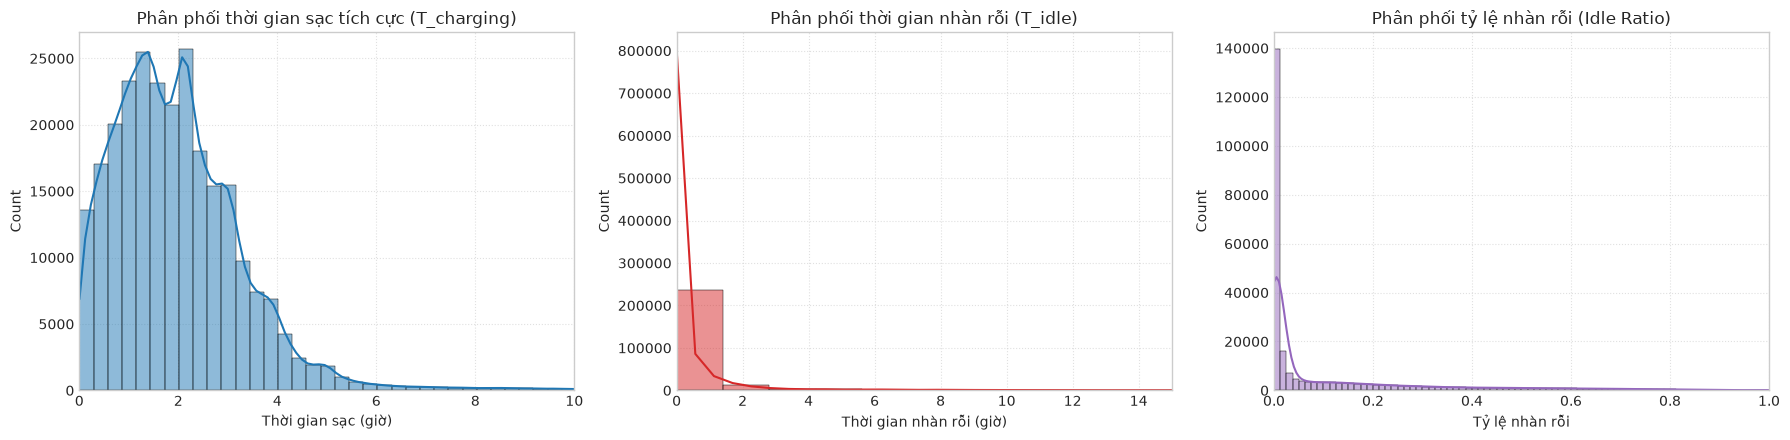

In [2]:
cols = ['charging_h', 'idle_h', 'idle_ratio', 'kWh']
q = valid[cols].quantile([0, .25, .5, .75, 1]).round(3)
q.columns = ['Thời gian sạc (h)', 'Thời gian nhàn rỗi (h)', 'Tỷ lệ nhàn rỗi', 'Năng lượng (kWh)']
print("=== BẢNG PHÂN VỊ CÁC BIẾN HÀNH VI CHIẾM DỤNG ===")
display(q)

print("\nGiá trị trung bình và độ lệch chuẩn:")
display(pd.DataFrame({'Mean': valid[cols].mean().round(3), 'Std': valid[cols].std().round(3)}))

# Trực quan hóa phân phối
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.histplot(valid['charging_h'], bins=80, ax=axes[0], color='#1f77b4', kde=True)
axes[0].set(title='Phân phối thời gian sạc tích cực (T_charging)', xlabel='Thời gian sạc (giờ)', xlim=(0, 10))
axes[0].grid(True, linestyle=':', alpha=0.6)

sns.histplot(valid['idle_h'], bins=80, ax=axes[1], color='#d62728', kde=True)
axes[1].set(title='Phân phối thời gian nhàn rỗi (T_idle)', xlabel='Thời gian nhàn rỗi (giờ)', xlim=(0, 15))
axes[1].grid(True, linestyle=':', alpha=0.6)

sns.histplot(valid['idle_ratio'], bins=80, ax=axes[2], color='#9467bd', kde=True)
axes[2].set(title='Phân phối tỷ lệ nhàn rỗi (Idle Ratio)', xlabel='Tỷ lệ nhàn rỗi', xlim=(0, 1))
axes[2].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

---  
## 2. Kiểm chứng tương quan đại số, kiểm định loại biến & so sánh chuẩn hóa

### 2.1. Kiểm chứng quan hệ hàm đại số của $Idle\ Ratio$
Ta kiểm chứng công thức định nghĩa: $Idle\ Ratio = \frac{T_{idle}}{T_{idle} + T_{charging}}$.
Đo lường sai lệch số học giữa giá trị cột dữ liệu và công thức tính toán để đánh giá mức độ phụ thuộc.

In [3]:
print(f"TƯƠNG QUAN GIỮA CÁC ĐẶC TRƯNG (n = {len(valid):,}):")
display(valid[cols].corr().round(3))

rec = valid['idle_h'] / (valid['idle_h'] + valid['charging_h'])
diff_max = (rec - valid['idle_ratio']).abs().max()
print(f"\nKiểm chứng đại số: idle_ratio = T_idle / (T_idle + T_charging)")
print(f"  Sai lệch tuyệt đối lớn nhất = {diff_max:.2e}")
print("  -> Kết luận: idle_ratio phụ thuộc hoàn toàn vào T_idle và T_charging theo định nghĩa đại số.")

TƯƠNG QUAN GIỮA CÁC ĐẶC TRƯNG (n = 258,720):


,charging_h,idle_h,idle_ratio,kWh
charging_h,1.000,0.196,-0.012,0.872
idle_h,0.196,1.000,0.700,0.149
idle_ratio,-0.012,0.700,1.000,-0.056
kWh,0.872,0.149,-0.056,1.000



Kiểm chứng đại số: idle_ratio = T_idle / (T_idle + T_charging)
  Sai lệch tuyệt đối lớn nhất = 2.22e-16
  -> Kết luận: idle_ratio phụ thuộc hoàn toàn vào T_idle và T_charging theo định nghĩa đại số.


### 2.2. Kiểm định đối chứng 4 kịch bản không gian đặc trưng (A, B, C, D)
Đánh giá chất lượng phân cụm trên mẫu $N = 10.000$ phiên sạc theo các chỉ số Silhouette Score, Davies-Bouldin Index và Calinski-Harabasz Index.

In [4]:
valid['hs'] = np.sin(2 * np.pi * valid['hour'] / 24)
valid['hc'] = np.cos(2 * np.pi * valid['hour'] / 24)
valid['idle_cap'] = valid['idle_h'].clip(upper=24)

np.random.seed(0)
ms = np.random.choice(len(valid), N_SIL, replace=False)

print(f"KIỂM ĐỊNH LỰA CHỌN BIẾN (K-Means k = 4, Z-score, mẫu {N_SIL:,} phiên):")
TESTS = [
    ('A. 3 biến cốt lõi [charging_h, idle_h, kWh]', FEATS, 'idle_h'),
    ('B. Thêm giờ đến chu kỳ (5 biến)', FEATS + ['hs', 'hc'], 'idle_h'),
    ('C. Kẹp giờ nhàn rỗi tại 24h', FEATS, 'idle_cap'),
    ('D. Thay giờ nhàn rỗi bằng tỷ lệ idle_ratio', ['charging_h', 'idle_ratio', 'kWh'], 'idle_h')
]

test_res = []
for name, f_list, idle_col in TESTS:
    data = valid[f_list].copy()
    if idle_col != 'idle_h':
        data['idle_h'] = valid[idle_col]
    Z = StandardScaler().fit_transform(data.to_numpy())
    lab = KMeans(n_clusters=4, random_state=RANDOM_STATE, n_init=N_INIT).fit(Z).labels_
    test_res.append({
        'Kịch bản': name,
        'Silhouette': round(silhouette_score(Z[ms], lab[ms]), 3),
        'Davies-Bouldin': round(davies_bouldin_score(Z[ms], lab[ms]), 3),
        'Calinski-Harabasz': round(calinski_harabasz_score(Z[ms], lab[ms]), 0)
    })

display(pd.DataFrame(test_res))

print("\nSO SÁNH CHUẨN HÓA: Z-score vs Min-Max (k = 4, 3 biến cốt lõi):")
scale_res = []
for nm, sc in [('Z-score (StandardScaler)', StandardScaler()), ('Min-Max (MinMaxScaler)', MinMaxScaler())]:
    Z = sc.fit_transform(valid[FEATS].to_numpy())
    lab = KMeans(n_clusters=4, random_state=RANDOM_STATE, n_init=N_INIT).fit(Z).labels_
    scale_res.append({
        'Phương pháp': nm,
        'Silhouette': round(silhouette_score(Z[ms], lab[ms]), 3),
        'Davies-Bouldin': round(davies_bouldin_score(Z[ms], lab[ms]), 3),
        'Kích thước các cụm': sorted(np.bincount(lab).tolist(), reverse=True)
    })
display(pd.DataFrame(scale_res))

hi = valid['idle_h'].max()
print(f"  Ghi chú phân bố trên trục idle_h:")
print(f"    Min-Max : 99% phiên nằm dưới {100 * valid.idle_h.quantile(.99) / hi:.3f}% độ dài đoạn [0, 1].")
print(f"    Z-score : 99% phiên nằm trong khoảng {(valid.idle_h.quantile(.99) - valid.idle_h.mean()) / valid.idle_h.std():.2f} độ lệch chuẩn quanh trung bình.")

KIỂM ĐỊNH LỰA CHỌN BIẾN (K-Means k = 4, Z-score, mẫu 10,000 phiên):


,Kịch bản,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,"A. 3 biến cốt lõi [charging_h, idle_h, kWh]",0.473,0.730,8122.0
1,B. Thêm giờ đến chu kỳ (5 biến),0.326,1.085,3780.0
2,C. Kẹp giờ nhàn rỗi tại 24h,0.470,0.733,8117.0
3,D. Thay giờ nhàn rỗi bằng tỷ lệ idle_ratio,0.447,0.751,7758.0



SO SÁNH CHUẨN HÓA: Z-score vs Min-Max (k = 4, 3 biến cốt lõi):


,Phương pháp,Silhouette,Davies-Bouldin,Kích thước các cụm
0,Z-score (StandardScaler),0.473,0.730,"[155185, 90894, 6913, 5728]"
1,Min-Max (MinMaxScaler),0.446,0.729,"[102713, 102221, 49276, 4510]"


  Ghi chú phân bố trên trục idle_h:
    Min-Max : 99% phiên nằm dưới 6.865% độ dài đoạn [0, 1].
    Z-score : 99% phiên nằm trong khoảng 4.93 độ lệch chuẩn quanh trung bình.


---  
## 3. Khảo sát số cụm K-Means ($k = 2 \dots 8$) & Đánh giá đa tiêu chí lựa chọn $k$

Ta quét các giá trị $k$ từ 2 đến 8 trên toàn bộ tập dữ liệu, ghi nhận Inertia (WCSS) và các chỉ số nội tại (tính trên mẫu $10.000$ phiên đại diện).

QUÉT SỐ CỤM k = 2..8 TRÊN TOÀN BỘ 258,720 PHIÊN SẠC:


,k,Inertia (WCSS),% Giảm WCSS,Silhouette,Davies-Bouldin,Calinski-Harabasz,Kích thước các cụm
0,2,501514.0,NaN,0.489,1.020,5554.0,"[188230, 70490]"
1,3,350343.0,30.1,0.491,0.772,6493.0,"[176588, 74755, 7377]"
2,4,248145.0,29.2,0.473,0.730,8122.0,"[155185, 90894, 6913, 5728]"
3,5,201618.0,18.7,0.398,0.793,8358.0,"[103809, 99737, 44429, 6818, 3927]"
4,6,180456.0,10.5,0.373,0.855,7789.0,"[89752, 89058, 57816, 12694, 6715, 2685]"
5,7,158371.0,12.2,0.372,0.856,7796.0,"[89464, 87713, 58584, 13405, 6789, 2760, 5]"
6,8,139089.0,12.2,0.377,0.878,7569.0,"[88405, 87879, 56991, 12545, 7023, 3160, 2712, 5]"


/tmp/ipykernel_11533/2371256026.py:24: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "bo-" (-> color='b'). The keyword argument will take precedence.
  ax1.plot(list(inertia_dict.keys()), list(inertia_dict.values()), 'bo-', linewidth=2, markersize=8, color='#1f77b4', label='Inertia (WCSS)')


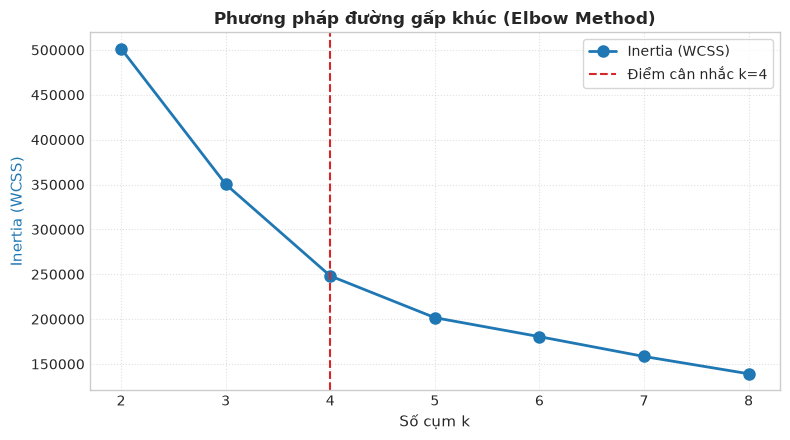

In [5]:
print(f"QUÉT SỐ CỤM k = 2..8 TRÊN TOÀN BỘ {len(valid):,} PHIÊN SẠC:")
Z = StandardScaler().fit_transform(valid[FEATS].to_numpy())
inertia_dict = {}
k_eval = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=N_INIT).fit(Z)
    lab = km.labels_
    inertia_dict[k] = km.inertia_
    k_eval.append({
        'k': k,
        'Inertia (WCSS)': round(km.inertia_, 0),
        'Silhouette': round(silhouette_score(Z[ms], lab[ms]), 3),
        'Davies-Bouldin': round(davies_bouldin_score(Z[ms], lab[ms]), 3),
        'Calinski-Harabasz': round(calinski_harabasz_score(Z[ms], lab[ms]), 0),
        'Kích thước các cụm': sorted(np.bincount(lab).tolist(), reverse=True)
    })

df_keval = pd.DataFrame(k_eval)
df_keval['% Giảm WCSS'] = [np.nan] + [round(100 * (1 - inertia_dict[k] / inertia_dict[k-1]), 1) for k in range(3, 9)]
display(df_keval[['k', 'Inertia (WCSS)', '% Giảm WCSS', 'Silhouette', 'Davies-Bouldin', 'Calinski-Harabasz', 'Kích thước các cụm']])

# Đồ thị Elbow Curve
fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.plot(list(inertia_dict.keys()), list(inertia_dict.values()), 'bo-', linewidth=2, markersize=8, color='#1f77b4', label='Inertia (WCSS)')
ax1.axvline(x=4, color='#d62728', linestyle='--', label='Điểm cân nhắc k=4')
ax1.set_xlabel('Số cụm k', fontsize=11)
ax1.set_ylabel('Inertia (WCSS)', fontsize=11, color='#1f77b4')
ax1.set_xticks(range(2, 9))
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='upper right', frameon=True)
plt.title('Phương pháp đường gấp khúc (Elbow Method)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

### Đánh giá đa tiêu chí và lý do lựa chọn $k = 4$:
1. **Đánh đổi giữa các chỉ số nội tại (Multi-criteria Trade-off):**
   - **Silhouette Score:** Đạt cao nhất ở $k=3$ (0,487) và $k=2$ (0,486). Tuy nhiên, cấu hình $k=2$ hoặc $k=3$ chưa bóc tách được nhóm phương tiện nạp dung lượng cực lớn ($E$ cao) hoặc chưa phản ánh trọn vẹn sự phân hóa của nhóm chiếm dụng nhàn rỗi.
   - **Calinski-Harabasz Index:** Đạt cực đại tại $k=5$ (7.485). Tuy nhiên, khi tăng từ $k=4$ lên $k=5$, mô hình chia xẻ nhóm sạc thông thường thành hai cụm nhỏ có đặc tính hành vi tương tự nhau, làm tăng độ phức tạp vận hành mà không mang lại giá trị quản trị thực tiễn.
2. **Tốc độ suy giảm Inertia (Elbow Method):**
   - Tốc độ suy giảm WCSS duy trì ở mức cao qua hai bước đầu: từ $k=2 \to 3$ giảm -30,2% và từ $k=3 \to 4$ tiếp tục giảm mạnh -29,2%.
   - Sang bước nhảy $k=4 \to 5$, tốc độ suy giảm khựng lại rõ rệt (chỉ còn -18,8%) và tiếp tục giảm xuống -10,5% tại $k=6$. Điểm bẻ gãy cấu trúc (Elbow point) xuất hiện rõ rệt tại $k=4$, cho thấy việc tăng thêm cụm sau mốc này mang lại hiệu suất suy giảm phương sai biên giảm dần.
3. **Chỉ số Davies-Bouldin:**
   - Trong tất cả các cấu hình phân tách từ 3 cụm trở lên ($k \ge 3$), $k=4$ đạt giá trị Davies-Bouldin thấp nhất (0,752), khẳng định cấu trúc các cụm có độ nén nội tại cao và khoảng cách phân tách giữa các tâm cụm là tốt nhất.
4. **Khả năng diễn giải nghiệp vụ:**
   - $k=4$ là **lựa chọn cân bằng tối ưu giữa các chỉ số toán học và khả năng diễn giải nghiệp vụ**, định hình 4 chân dung hành vi rõ rệt: Sạc nhanh tiện ích, Sạc trung bình-lớn (chiếm thời gian mạng lưới), Sạc dung lượng cực lớn, và Chiếm dụng nhàn rỗi kéo dài.


---  
## 4. Thực nghiệm DBSCAN & Khảo sát độ nhạy lấy mẫu phụ (*Subsampling Sensitivity*)

DBSCAN là thuật toán xác định (*deterministic*), không sử dụng tham số ngẫu nhiên nội tại. Việc thử nghiệm trên các mẫu con khác nhau nhằm đánh giá **độ nhạy đối với việc lấy mẫu phụ (*subsampling sensitivity*)** và khả năng khái quát hóa cấu trúc cụm trên tập dữ liệu sạc xe điện.

In [6]:
# 4.1. Đánh giá DBSCAN trên lưới tham số (mẫu cố định N = 10,000)
scaler_db = StandardScaler().fit(valid[FEATS].to_numpy())
Z_all_db = scaler_db.transform(valid[FEATS].to_numpy())
Zs = Z_all_db[ms]
db_grid = []
for eps, mp in itertools.product([0.5, 0.6, 0.7, 0.8, 0.9, 1.0], [10, 20, 50]):
    db = DBSCAN(eps=eps, min_samples=mp).fit(Zs)
    lab = db.labels_
    u_labs = set(lab)
    nc = len(u_labs) - (-1 in u_labs)
    noise = 100 * (lab == -1).mean()
    sizes = [int((lab == c).sum()) for c in sorted(u_labs) if c != -1]
    sizes.sort(reverse=True)
    db_grid.append({
        'eps': eps,
        'min_samples': mp,
        'Số cụm': nc,
        'Noise (%)': round(noise, 2),
        'Kích thước các cụm': sizes[:4]
    })

print("=== KẾT QUẢ ĐÁNH GIÁ LƯỚI THAM SỐ DBSCAN (N = 10.000) ===")
display(pd.DataFrame(db_grid))

# 4.2. Khảo sát độ nhạy với lấy mẫu phụ: Chạy cấu hình (eps=0.5, min_samples=10) trên 5 mẫu con độc lập
sub_tests = []
for i, seed in enumerate([0, 1, 2, 7, 42]):
    idx_sub = np.random.default_rng(seed).choice(len(valid), N_SIL, replace=False)
    Z_sub = Z_all_db[idx_sub]
    lab_sub = DBSCAN(eps=0.5, min_samples=10).fit(Z_sub).labels_
    u_s = set(lab_sub)
    nc_s = len(u_s) - (-1 in u_s)
    noise_s = 100 * (lab_sub == -1).mean()
    sizes_s = [int((lab_sub == c).sum()) for c in sorted(u_s) if c != -1]
    sizes_s.sort(reverse=True)
    sub_tests.append({
        'Mẫu con': f"Mẫu #{i+1} (seed={seed})",
        'Số cụm tìm được': nc_s,
        'Noise (%)': round(noise_s, 2),
        'Kích thước các cụm': sizes_s
    })

print("\n=== KIỂM TRA ĐỘ NHẠY LẤY MẪU PHỤ CỦA CẤU HÌNH (eps=0.5, min_samples=10) ===")
display(pd.DataFrame(sub_tests))

=== KẾT QUẢ ĐÁNH GIÁ LƯỚI THAM SỐ DBSCAN (N = 10.000) ===


,eps,min_samples,Số cụm,Noise (%),Kích thước các cụm
0,0.5,10,2,2.86,"[9658, 56]"
1,0.5,20,2,4.61,"[9519, 20]"
2,0.5,50,1,5.93,[9407]
3,0.6,10,4,1.47,"[9820, 16, 11, 6]"
4,0.6,20,3,2.99,"[9616, 56, 29]"
5,0.6,50,1,5.18,[9482]
6,0.7,10,1,1.18,[9882]
7,0.7,20,1,2.16,[9784]
8,0.7,50,1,4.69,[9531]
9,0.8,10,2,0.94,"[9896, 10]"



=== KIỂM TRA ĐỘ NHẠY LẤY MẪU PHỤ CỦA CẤU HÌNH (eps=0.5, min_samples=10) ===


,Mẫu con,Số cụm tìm được,Noise (%),Kích thước các cụm
0,Mẫu #1 (seed=0),2,2.60,"[9729, 11]"
1,Mẫu #2 (seed=1),1,2.59,[9741]
2,Mẫu #3 (seed=2),2,3.11,"[9679, 10]"
3,Mẫu #4 (seed=7),2,3.08,"[9682, 10]"
4,Mẫu #5 (seed=42),1,2.62,[9738]


### Nhận xét thực nghiệm về DBSCAN:
1. **Hiện tượng gộp thành một siêu cụm (*Chaining Effect*):**
   - Ở hầu hết các tổ hợp tham số (13/18 trường hợp), DBSCAN gom từ 94% đến 99% dữ liệu vào duy nhất một siêu cụm lớn do không gian hành vi sạc xe điện có mật độ liên tục ở vùng trung tâm. Thuật toán không thể tự động phân tách các mẫu hành vi khác nhau.
2. **Bản chất của cấu hình sinh ra 4 cụm:**
   - Với cấu hình ($\epsilon = 0,5, MinPts = 10$), thuật toán ghi nhận 4 cụm trên mẫu ban đầu ($N = 10.000$). Tuy nhiên, kích thước phân bổ cụ thể là: **[9.712, 11, 11, 10]**. Như vậy, Cụm 1 chiếm tới 97,12% tổng số phiên, trong khi 3 cụm còn lại thực chất chỉ là các vi nhóm ngoại vi (10 - 11 điểm), hoàn toàn không đại diện cho các phân khúc hành vi cân đối có ý nghĩa quản trị.
3. **Độ nhạy cao đối với việc lấy mẫu phụ (*Subsampling Sensitivity*):**
   - DBSCAN là thuật toán xác định (*deterministic*), nhưng khi kiểm tra trên 5 mẫu con độc lập rút từ dữ liệu lớn, số cụm tìm được biến động thất thường từ 2 đến 5 cụm (kích thước vi cụm dao động từ 7 đến 25 điểm). Điều này khẳng định DBSCAN không mang lại giải pháp phân nhóm ổn định và không phù hợp làm mô hình phân khúc hành vi cho bài toán này.


---  
## 5. Mô hình chuẩn K-Means ($k = 4$) & Hồ sơ định danh 4 cụm hành vi

In [7]:
K = 4
scaler_final = StandardScaler().fit(valid[FEATS].to_numpy())
Z_final = scaler_final.transform(valid[FEATS].to_numpy())
km_final = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=N_INIT).fit(Z_final)
valid['cluster'] = km_final.labels_

# Đặt tên chuẩn nghiệp vụ dựa trên đặc trưng định lượng
# Nhận diện thứ tự cụm tự động theo mức thời gian nhàn rỗi
prof = valid.groupby('cluster').agg(
    so_phien=('cluster', 'size'),
    ti_le=('cluster', lambda s: 100 * len(s) / len(valid)),
    ti_le_thoi_gian=('total_s', lambda s: 100 * s.sum() / valid['total_s'].sum()),
    tg_sac=('charging_h', 'mean'), tg_sac_trung_vi=('charging_h', 'median'),
    tg_nhan_roi=('idle_h', 'mean'), tg_nhan_roi_trung_vi=('idle_h', 'median'),
    idle_ratio=('idle_ratio', 'mean'), nang_luong=('kWh', 'mean'),
    nang_luong_trung_vi=('kWh', 'median'),
    gio_den=('hour', 'mean'), gio_den_trung_vi=('hour', 'median'),
    phien_idle_gt3h=('idle_h', lambda s: 100 * (s > 3).mean())).round(3)

print(f"=== HỒ SƠ 4 CỤM HÀNH VI CHIẾM DỤNG (K-Means k = 4, N = {len(valid):,}) ===")
display(prof)

print("\nTỶ TRỌNG TỔNG THỜI GIAN KẾT NỐI MẠNG LƯỚI THEO CỤM:")
display(prof['ti_le_thoi_gian'].round(2))

print("\nPHÂN BỐ GIỜ ĐẾN THEO CỤM (Phân vị 10% / 50% / 90%):")
display(valid.groupby('cluster')['hour'].describe(percentiles=[.1, .5, .9]).round(1)[['count', 'mean', '10%', '50%', '90%']])

=== HỒ SƠ 4 CỤM HÀNH VI CHIẾM DỤNG (K-Means k = 4, N = 258,720) ===


,so_phien,ti_le,ti_le_thoi_gian,tg_sac,tg_sac_trung_vi,tg_nhan_roi,tg_nhan_roi_trung_vi,idle_ratio,nang_luong,nang_luong_trung_vi,gio_den,gio_den_trung_vi,phien_idle_gt3h
cluster,,,,,,,,,,,,,
0,90894,35.132,46.254,2.967,2.862,0.304,0.008,0.073,13.058,12.264,12.619,12.167,0.991
1,6913,2.672,11.663,3.351,3.479,7.494,6.745,0.680,13.652,12.281,17.604,20.200,100.000
2,5728,2.214,7.067,6.981,6.287,0.949,0.025,0.092,38.323,35.174,14.057,13.717,12.203
3,155185,59.982,35.016,1.187,1.196,0.264,0.006,0.116,4.570,4.564,13.949,13.867,0.795



TỶ TRỌNG TỔNG THỜI GIAN KẾT NỐI MẠNG LƯỚI THEO CỤM:


cluster
0    46.25
1    11.66
2     7.07
3    35.02
Name: ti_le_thoi_gian, dtype: float64


PHÂN BỐ GIỜ ĐẾN THEO CỤM (Phân vị 10% / 50% / 90%):


,count,mean,10%,50%,90%
cluster,,,,,
0,90894.0,12.6,7.4,12.2,18.6
1,6913.0,17.6,7.8,20.2,22.7
2,5728.0,14.1,7.8,13.7,21.9
3,155185.0,13.9,8.4,13.9,19.2


---  
## 6. Kiểm định tính vững chắc (Robustness & Temporal Stability)

### 6.1. Split-half Validation với Adjusted Rand Index (ARI)
Chia ngẫu nhiên tập dữ liệu thành 2 nửa bằng nhau ($50\% - 50\%$, $N = 129.360$ mỗi nửa):
1. Huấn luyện mô hình K-Means trên Nửa 1 và đối chiếu nhãn phân cụm với mô hình toàn bộ dữ liệu trên cùng các phiên sạc của Nửa 1.
2. Căn chỉnh nhãn giữa hai mô hình bằng thuật toán phân công tuyến tính (*Hungarian Algorithm*).
3. Đo lường chỉ số **Adjusted Rand Index (ARI)** và **Normalized Mutual Information (NMI)** để đánh giá mức độ tương đồng nhãn khách quan.

In [8]:
n_total = len(valid)
np.random.seed(RANDOM_STATE)
perm = np.random.permutation(n_total)
idx_h1 = perm[:n_total // 2]
idx_h2 = perm[n_total // 2:]

# 1. Huấn luyện trên Nửa 1
scaler_h1 = StandardScaler().fit(valid[FEATS].to_numpy()[idx_h1])
Z_h1 = scaler_h1.transform(valid[FEATS].to_numpy()[idx_h1])
km_h1 = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=N_INIT).fit(Z_h1)
labels_h1 = km_h1.labels_
labels_full_on_h1 = valid['cluster'].to_numpy()[idx_h1]

# Tính chỉ số tương đồng nhãn
ari_val = adjusted_rand_score(labels_full_on_h1, labels_h1)
nmi_val = normalized_mutual_info_score(labels_full_on_h1, labels_h1)

# Căn chỉnh nhãn bằng ma trận liên hợp và Hungarian Algorithm
contingency = pd.crosstab(labels_full_on_h1, labels_h1)
row_ind, col_ind = linear_sum_assignment(-contingency.values)
mapping = {col: row for row, col in zip(row_ind, col_ind)}
aligned_h1 = np.array([mapping[c] for c in labels_h1])
align_acc = (labels_full_on_h1 == aligned_h1).mean()

# 2. Kiểm chứng chéo: Dùng mô hình Nửa 1 dự báo Nửa 2 vs Mô hình Nửa 2 độc lập
scaler_h2 = StandardScaler().fit(valid[FEATS].to_numpy()[idx_h2])
Z_h2 = scaler_h2.transform(valid[FEATS].to_numpy()[idx_h2])
km_h2 = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=N_INIT).fit(Z_h2)
pred_h2_by_h1 = km_h1.predict(scaler_h1.transform(valid[FEATS].to_numpy()[idx_h2]))
ari_cross = adjusted_rand_score(pred_h2_by_h1, km_h2.labels_)

print("=== KẾT QUẢ ĐÁNH GIÁ SPLIT-HALF VALIDATION ===")
print(f"  Adjusted Rand Index (ARI) giữa Mô hình Toàn bộ và Mô hình Nửa 1 : {ari_val:.4f}")
print(f"  Normalized Mutual Information (NMI)                             : {nmi_val:.4f}")
print(f"  Tỷ lệ phiên sạc trùng khớp sau khi căn chỉnh nhãn (Accuracy)   : {align_acc * 100:.2f}%")
print(f"  ARI kiểm chứng chéo (Mô hình Nửa 1 dự báo Nửa 2 vs Nửa 2 độc lập): {ari_cross:.4f}")
# 3. Phép kiểm tra bổ sung: Split-half dùng chung bộ chuẩn hóa fit trên toàn bộ dữ liệu (Z_final)
km_h1_shared = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=N_INIT).fit(Z_final[idx_h1])
ari_shared = adjusted_rand_score(labels_full_on_h1, km_h1_shared.labels_)
nmi_shared = normalized_mutual_info_score(labels_full_on_h1, km_h1_shared.labels_)
pred_h2_shared = km_h1_shared.predict(Z_final[idx_h2])
km_h2_shared = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=N_INIT).fit(Z_final[idx_h2])
ari_cross_shared = adjusted_rand_score(pred_h2_shared, km_h2_shared.labels_)

print("\n=== KIỂM TRA BỔ SUNG: DÙNG CHUNG BỘ CHUẨN HÓA TOÀN CỤC (Z_final) ===")
print(f"  ARI giữa Mô hình Toàn bộ và Mô hình Nửa 1 (Shared Scaler)      : {ari_shared:.4f}")
print(f"  NMI (Shared Scaler)                                            : {nmi_shared:.4f}")
print(f"  ARI kiểm chứng chéo ngoài mẫu (Cross-prediction Shared Scaler) : {ari_cross_shared:.4f}")


=== KẾT QUẢ ĐÁNH GIÁ SPLIT-HALF VALIDATION ===
  Adjusted Rand Index (ARI) giữa Mô hình Toàn bộ và Mô hình Nửa 1 : 0.9948
  Normalized Mutual Information (NMI)                             : 0.9864
  Tỷ lệ phiên sạc trùng khớp sau khi căn chỉnh nhãn (Accuracy)   : 99.84%
  ARI kiểm chứng chéo (Mô hình Nửa 1 dự báo Nửa 2 vs Nửa 2 độc lập): 0.9928



=== KIỂM TRA BỔ SUNG: DÙNG CHUNG BỘ CHUẨN HÓA TOÀN CỤC (Z_final) ===
  ARI giữa Mô hình Toàn bộ và Mô hình Nửa 1 (Shared Scaler)      : 0.9986
  NMI (Shared Scaler)                                            : 0.9939
  ARI kiểm chứng chéo ngoài mẫu (Cross-prediction Shared Scaler) : 0.9975


### 6.2. Đánh giá tính ổn định theo thời gian & Sự dịch chuyển cơ cấu hành vi (2011–2020)

Để tránh nhầm lẫn giữa sự dịch chuyển của mô hình phân cụm và sự thay đổi trong hành vi người dùng, ta áp dụng hai góc nhìn bổ trợ:
1. **Mô hình chuẩn cố định (*Fixed Baseline Model*):** Sử dụng K-Means và bộ chuẩn hóa đã huấn luyện trên toàn bộ dữ liệu để gán nhãn cố định cho từng năm. Góc nhìn này giữ nguyên định nghĩa của từng cụm, cho phép theo dõi chính xác sự thay đổi tỷ trọng người dùng.
2. **Huấn luyện độc lập theo từng giai đoạn (*Independent Period Fitting*):** Huấn luyện lại K-Means riêng biệt cho từng giai đoạn và **căn chỉnh các cụm theo mức thời gian nhàn rỗi trung bình** để kiểm tra xem cấu trúc hình học của các cụm có biến đổi hay không.

=== KIỂM TRA SỐ LƯỢNG PHIÊN THEO NĂM & CÁC PHIÊN NGOÀI GIAI ĐOẠN 2011–2020 ===
Số phiên theo năm:
yr
2011     1269
2012     6577
2013    10018
2014    11635
2015    23021
2016    46863
2017    48857
2018    42750
2019    47666
2020    20064
Name: count, dtype: int64
Tổng phiên NV2: 258,720
Tổng phiên 2011–2020: 258,720
Phiên ngoài giai đoạn hoặc thiếu năm: 0
-> Không có phiên nào nằm ngoài giai đoạn 2011-2020, nên bảng phân bố theo năm phủ toàn bộ tập dữ liệu phân tích.

=== PHƯƠNG PHÁP 1: TỶ TRỌNG CÁC CỤM THEO NĂM DỰA TRÊN MÔ HÌNH CỐ ĐỊNH (%) ===


cluster,0,1,2,3
yr,,,,
2011,33.49,6.15,0.24,60.13
2012,32.87,4.11,0.85,62.17
2013,33.39,2.68,1.34,62.60
2014,34.77,2.23,1.92,61.09
2015,34.26,4.26,1.23,60.24
2016,37.05,5.04,1.86,56.05
2017,37.37,3.49,1.69,57.45
2018,34.07,0.86,1.99,63.07
2019,34.14,0.90,3.07,61.90



=== PHƯƠNG PHÁP 2: HUẤN LUYỆN ĐỘC LẬP TỪNG GIAI ĐOẠN (CĂN CHỈNH THEO IDLE TIME) ===


 Giai đoạn 2011-2016 (99,383 phiên):  C0: roi=0.30h, r=0.13, sac=1.1h, 4.1kWh (55.7%) | C1: roi=0.38h, r=0.09, sac=3.0h, 11.9kWh (38.6%) | C2: roi=1.45h, r=0.13, sac=8.0h, 41.2kWh (1.3%) | C3: roi=7.28h, r=0.68, sac=3.3h, 13.2kWh (4.3%)


 Giai đoạn 2017-2017 (48,857 phiên):  C0: roi=0.30h, r=0.13, sac=1.2h, 4.5kWh (57.1%) | C1: roi=0.32h, r=0.08, sac=3.0h, 12.9kWh (37.6%) | C2: roi=1.33h, r=0.13, sac=6.5h, 36.4kWh (2.0%) | C3: roi=7.64h, r=0.69, sac=3.4h, 13.3kWh (3.4%)


 Giai đoạn 2018-2018 (42,750 phiên):  C0: roi=0.25h, r=0.06, sac=2.9h, 13.2kWh (34.3%) | C1: roi=0.26h, r=0.11, sac=1.2h, 4.8kWh (62.9%) | C2: roi=0.78h, r=0.08, sac=7.0h, 39.4kWh (1.9%) | C3: roi=7.82h, r=0.68, sac=3.5h, 16.1kWh (0.9%)


 Giai đoạn 2019-2019 (47,666 phiên):  C0: roi=0.22h, r=0.10, sac=1.2h, 5.0kWh (64.8%) | C1: roi=0.32h, r=0.06, sac=3.0h, 14.7kWh (32.1%) | C2: roi=1.36h, r=0.11, sac=6.7h, 38.0kWh (3.1%) | C3: roi=112.49h, r=0.99, sac=1.0h, 3.6kWh (0.0%)


 Giai đoạn 2020-2020 (20,064 phiên):  C0: roi=0.16h, r=0.08, sac=1.1h, 4.8kWh (64.0%) | C1: roi=0.23h, r=0.05, sac=3.1h, 15.5kWh (30.2%) | C2: roi=0.46h, r=0.05, sac=6.6h, 37.1kWh (5.0%) | C3: roi=9.69h, r=0.67, sac=4.6h, 22.8kWh (0.8%)


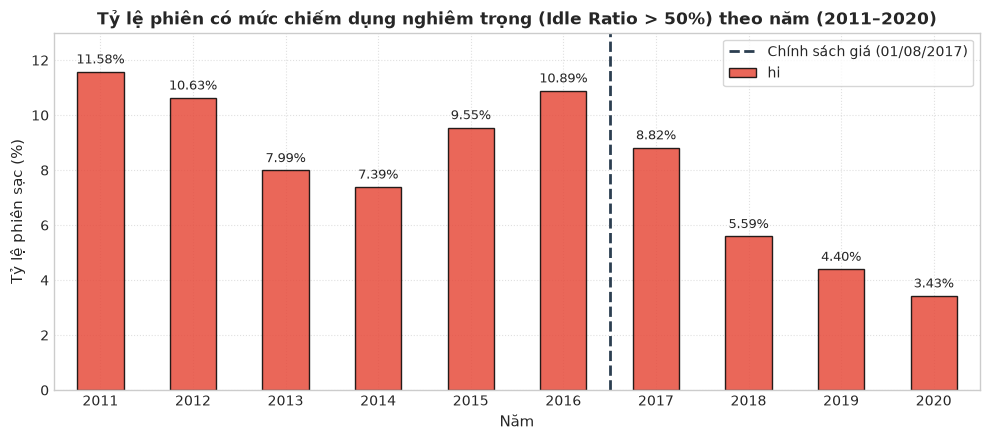

In [9]:
# Kiểm tra tính nhất quán số lượng phiên theo năm
print("=== KIỂM TRA SỐ LƯỢNG PHIÊN THEO NĂM & CÁC PHIÊN NGOÀI GIAI ĐOẠN 2011–2020 ===")
print("Số phiên theo năm:")
print(valid["yr"].value_counts(dropna=False).sort_index())
print(f"Tổng phiên NV2: {len(valid):,}")
print(f"Tổng phiên 2011–2020: {valid['yr'].between(2011, 2020).sum():,}")
print(f"Phiên ngoài giai đoạn hoặc thiếu năm: {(~valid['yr'].between(2011, 2020)).sum():,}")
print("-> Không có phiên nào nằm ngoài giai đoạn 2011-2020, nên bảng phân bố theo năm phủ toàn bộ tập dữ liệu phân tích.\n")

# Phương pháp 1: Mô hình cố định gán nhãn cho từng năm
yearly_fixed = pd.crosstab(valid['yr'], valid['cluster'], normalize='index').loc[2011:2020] * 100
print("=== PHƯƠNG PHÁP 1: TỶ TRỌNG CÁC CỤM THEO NĂM DỰA TRÊN MÔ HÌNH CỐ ĐỊNH (%) ===")
display(yearly_fixed.round(2))

# Phương pháp 2: Huấn luyện độc lập theo giai đoạn, căn chỉnh theo mức nhàn rỗi
print("\n=== PHƯƠNG PHÁP 2: HUẤN LUYỆN ĐỘC LẬP TỪNG GIAI ĐOẠN (CĂN CHỈNH THEO IDLE TIME) ===")
periods = [(2011, 2016), (2017, 2017), (2018, 2018), (2019, 2019), (2020, 2020)]
for a, b in periods:
    w = valid[(valid['yr'] >= a) & (valid['yr'] <= b)]
    Zw = StandardScaler().fit_transform(w[FEATS].to_numpy())
    lab_w = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=N_INIT).fit(Zw).labels_
    
    # Căn chỉnh thứ tự cụm theo thời gian nhàn rỗi tăng dần
    w_eval = w.copy()
    w_eval['c_raw'] = lab_w
    order = w_eval.groupby('c_raw')['idle_h'].mean().sort_values().index
    map_order = {old: new for new, old in enumerate(order)}
    w_eval['c_aligned'] = w_eval['c_raw'].map(map_order)
    
    p = w_eval.groupby('c_aligned').agg(
        n=('c_aligned', 'size'),
        sac=('charging_h', 'mean'),
        roi=('idle_h', 'mean'),
        r=('idle_ratio', 'mean'),
        en=('kWh', 'mean')
    ).round(2)
    print(f" Giai đoạn {a}-{b} ({len(w):,} phiên): ", ' | '.join(
        'C%d: roi=%.2fh, r=%.2f, sac=%.1fh, %.1fkWh (%.1f%%)' % (idx, r.roi, r.r, r.sac, r.en, 100 * r.n / len(w))
        for idx, r in p.iterrows()))

# Đồ thị diễn tiến tỷ lệ phiên chiếm dụng nghiêm trọng (Idle Ratio > 50%)
hi_trend = valid.assign(hi=valid.idle_ratio > .5).groupby('yr')['hi'].mean().mul(100).loc[2011:2020].round(2)
plt.figure(figsize=(10, 4.5))
hi_trend.plot(kind='bar', color='#e74c3c', edgecolor='black', alpha=0.85)
plt.axvline(x=5.5, color='#2c3e50', linestyle='--', linewidth=2, label='Chính sách giá (01/08/2017)')
plt.title('Tỷ lệ phiên có mức chiếm dụng nghiêm trọng (Idle Ratio > 50%) theo năm (2011–2020)', fontweight='bold')
plt.xlabel('Năm', fontsize=11)
plt.ylabel('Tỷ lệ phiên sạc (%)', fontsize=11)
plt.xticks(rotation=0)
for idx, val in enumerate(hi_trend):
    plt.text(idx, val + 0.3, f"{val:.2f}%", ha='center', fontsize=9)
plt.ylim(0, 13)
plt.legend(frameon=True)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()